In [ ]:
!pip install -q -U datasets huggingface_hub pillow scikit-learn tqdm

In [1]:
import csv
import random
from pathlib import Path

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt


from io import BytesIO

from PIL import Image
from datasets import load_dataset
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from torchvision.models import (
    convnext_small,
    ConvNeXt_Small_Weights
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from tqdm.auto import tqdm

In [ ]:
DATASET_NAME = "saberzl/SID_Set"

SEED = 42
IMAGE_SIZE = (224, 224)

TARGET_PER_CLASS = {
    0: 16_666,
    1: 16_667,
    2: 16_667,
}

CLASS_NAMES = {
    0: "real",
    1: "full_synthetic",
    2: "tampered",
}

In [ ]:
PROCESSED_DIR = Path(
    "/kaggle/working/sid_set_50000_processed"
)

CSV_PATH = PROCESSED_DIR / "labels.csv"

TOTAL_TARGET = sum(
    TARGET_PER_CLASS.values()
)

print("Total target:", TOTAL_TARGET)

In [ ]:
SPLIT_QUOTAS = {}

for label, total in TARGET_PER_CLASS.items():

    train_n = round(
        total * 0.70
    )

    val_n = round(
        total * 0.15
    )

    test_n = (
        total
        - train_n
        - val_n
    )

    SPLIT_QUOTAS[label] = {
        "train": train_n,
        "val": val_n,
        "test": test_n,
    }

SPLIT_QUOTAS

In [ ]:
SPLIT_PLAN = {}

for label, quotas in SPLIT_QUOTAS.items():

    plan = (
        ["train"] * quotas["train"]
        + ["val"] * quotas["val"]
        + ["test"] * quotas["test"]
    )

    random.Random(
        SEED + label
    ).shuffle(plan)

    SPLIT_PLAN[label] = plan

In [ ]:
if CSV_PATH.exists():

    raise FileExistsError(
        f"Dataset already exists at: {PROCESSED_DIR}"
    )


for split in (
    "train",
    "val",
    "test"
):

    for class_name in CLASS_NAMES.values():

        (
            PROCESSED_DIR
            / split
            / class_name
        ).mkdir(
            parents=True,
            exist_ok=True
        )

In [ ]:
dataset = load_dataset(
    DATASET_NAME,
    split="train",
    streaming=True,
)

dataset = dataset.shuffle(
    seed=SEED,
    buffer_size=2000,
)

print(dataset)

In [ ]:
def to_pil_image(image):

    if isinstance(
        image,
        Image.Image
    ):

        return image.convert(
            "RGB"
        )


    if isinstance(
        image,
        bytes
    ):

        return Image.open(
            BytesIO(image)
        ).convert(
            "RGB"
        )


    if isinstance(
        image,
        dict
    ):

        if image.get(
            "bytes"
        ) is not None:

            return Image.open(
                BytesIO(
                    image["bytes"]
                )
            ).convert(
                "RGB"
            )


        if image.get(
            "path"
        ) is not None:

            return Image.open(
                image["path"]
            ).convert(
                "RGB"
            )


    raise TypeError(
        f"Unsupported image type: {type(image)}"
    )

In [ ]:
counts = {
    label: 0
    for label in TARGET_PER_CLASS
}


split_counts = {

    label: {
        "train": 0,
        "val": 0,
        "test": 0
    }

    for label in TARGET_PER_CLASS
}


metadata = []

In [ ]:
progress = tqdm(
    total=TOTAL_TARGET,
    desc="Processing dataset",
)

In [ ]:
for sample in dataset:

    try:

        label = int(
            sample["label"]
        )


        if label not in TARGET_PER_CLASS:
            continue


        if (
            counts[label]
            >= TARGET_PER_CLASS[label]
        ):
            continue


        split_name = SPLIT_PLAN[
            label
        ][
            counts[label]
        ]


        image = to_pil_image(
            sample["image"]
        )


        image = image.resize(
            IMAGE_SIZE,
            Image.Resampling.LANCZOS
        )


        class_name = CLASS_NAMES[
            label
        ]


        index_in_split = (
            split_counts[
                label
            ][
                split_name
            ]
        )


        output_dir = (
            PROCESSED_DIR
            / split_name
            / class_name
        )


        filename = (
            f"{class_name}_"
            f"{index_in_split:06d}.png"
        )


        output_path = (
            output_dir
            / filename
        )


        image.save(
            output_path,
            format="PNG"
        )


        metadata.append({

            "path": str(
                output_path.relative_to(
                    PROCESSED_DIR
                )
            ),

            "label": label,

            "class_name": class_name,

            "split": split_name
        })


        counts[label] += 1

        split_counts[
            label
        ][
            split_name
        ] += 1


        progress.update(1)


        if all(

            counts[label]
            >= TARGET_PER_CLASS[label]

            for label
            in TARGET_PER_CLASS

        ):
            break


    except Exception as e:

        print(
            f"Skipped sample: {e}"
        )


progress.close()

In [ ]:
print("Per-class counts:")

print(counts)


print("\nSplit counts:")

print(split_counts)


print(
    "\nTotal:",
    sum(counts.values())
)

In [ ]:
with open(
    CSV_PATH,
    "w",
    newline="",
    encoding="utf-8"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=[
            "path",
            "label",
            "class_name",
            "split"
        ],
    )

    writer.writeheader()

    writer.writerows(
        metadata
    )


print(
    "Saved:",
    CSV_PATH
)

In [ ]:
total_saved = 0


for split in (
    "train",
    "val",
    "test"
):

    split_total = 0

    print(
        f"\n{split.upper()}"
    )


    for class_name in CLASS_NAMES.values():

        folder = (
            PROCESSED_DIR
            / split
            / class_name
        )


        count = len(
            list(
                folder.glob(
                    "*.png"
                )
            )
        )


        split_total += count


        print(
            f"{class_name}: {count}"
        )


    total_saved += split_total


    print(
        f"Total {split}: {split_total}"
    )


print(
    "\nTotal saved:",
    total_saved
)


print(
    "Expected:",
    TOTAL_TARGET
)


assert (
    total_saved
    == TOTAL_TARGET
)

# قؤاءة البيانات


In [2]:

DATA_DIR = Path(
    "/kaggle/input/notebooks/overgame1234/cool2/sid_set_50000_processed"
)

TRAIN_DIR = DATA_DIR / "train"
VAL_DIR   = DATA_DIR / "val"
TEST_DIR  = DATA_DIR / "test"




In [9]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


train_dataset = datasets.ImageFolder(
    TRAIN_DIR,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    VAL_DIR,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=eval_transform
)

print("Classes:", train_dataset.classes)
print("Mapping:", train_dataset.class_to_idx)

print("Train:", len(train_dataset))
print("Val:", len(val_dataset))
print("Test:", len(test_dataset))

Classes: ['full_synthetic', 'real', 'tampered']
Mapping: {'full_synthetic': 0, 'real': 1, 'tampered': 2}
Train: 35000
Val: 7500
Test: 7500


In [10]:
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))
print("Test batches:", len(test_loader))

Train batches: 1094
Val batches: 235
Test batches: 235


In [11]:
import torch
import torch.nn as nn

from torchvision.models import (
    convnext_small,
    ConvNeXt_Small_Weights
)

weights = ConvNeXt_Small_Weights.IMAGENET1K_V1

model = convnext_small(
    weights=weights
)

model.classifier[2] = nn.Linear(
    model.classifier[2].in_features,
    3
)

model = model.to(device)

print(model.classifier)

Downloading: "https://download.pytorch.org/models/convnext_small-0c510722.pth" to /root/.cache/torch/hub/checkpoints/convnext_small-0c510722.pth


100%|██████████| 192M/192M [00:01<00:00, 169MB/s]  


Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=768, out_features=3, bias=True)
)


In [12]:
# Freeze كل الموديل
for param in model.parameters():
    param.requires_grad = False

# فتح آخر أجزاء ConvNeXt
for param in model.features[-2:].parameters():
    param.requires_grad = True

# فتح classifier
for param in model.classifier.parameters():
    param.requires_grad = True

In [13]:
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

print(
    f"Trainable percentage: "
    f"{100 * trainable_params / total_params:.2f}%"
)

Total parameters: 49,456,995
Trainable parameters: 15,474,435
Trainable percentage: 31.29%


In [14]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=1e-5,
    weight_decay=1e-3
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

In [15]:
from tqdm.auto import tqdm

def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    scaler,
    device
):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(
        loader,
        desc="Training"
    )

    for images, labels in progress:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.amp.autocast(
            device_type="cuda",
            enabled=torch.cuda.is_available()
        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = outputs.argmax(
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

        progress.set_postfix(
            loss=f"{loss.item():.4f}",
            acc=f"{correct / total:.2%}"
        )

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [16]:
def evaluate(
    model,
    loader,
    criterion,
    device,
    desc="Validation"
):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        progress = tqdm(
            loader,
            desc=desc
        )

        for images, labels in progress:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            with torch.amp.autocast(
                device_type="cuda",
                enabled=torch.cuda.is_available()
            ):

                outputs = model(images)

                loss = criterion(
                    outputs,
                    labels
                )

            running_loss += (
                loss.item() * images.size(0)
            )

            predictions = outputs.argmax(
                dim=1
            )

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    return epoch_loss, epoch_acc

In [17]:
from pathlib import Path

CHECKPOINT_DIR = Path(
    "/kaggle/working/convnext_small_checkpoints"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

best_val_loss = float("inf")
best_val_acc = 0.0

epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

print(CHECKPOINT_DIR)

/kaggle/working/convnext_small_checkpoints


In [18]:
EPOCHS = 15
PATIENCE = 4

for epoch in range(EPOCHS):

    print()
    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print("=" * 60)

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        optimizer,
        criterion,
        scaler,
        device
    )

    val_loss, val_acc = evaluate(
        model,
        val_loader,
        criterion,
        device,
        desc="Validation"
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print()
    print(f"Train Loss:     {train_loss:.4f}")
    print(f"Train Accuracy: {train_acc:.2%}")

    print(f"Val Loss:       {val_loss:.4f}")
    print(f"Val Accuracy:   {val_acc:.2%}")

    print(
        "Learning Rate:",
        optimizer.param_groups[0]["lr"]
    )

    checkpoint = {
        "epoch": epoch + 1,

        "model_state_dict":
            model.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "scheduler_state_dict":
            scheduler.state_dict(),

        "scaler_state_dict":
            scaler.state_dict(),

        "train_loss":
            train_loss,

        "train_acc":
            train_acc,

        "val_loss":
            val_loss,

        "val_acc":
            val_acc,

        "classes":
            train_dataset.classes,

        "class_to_idx":
            train_dataset.class_to_idx
    }

    # حفظ checkpoint لكل epoch
    torch.save(
        checkpoint,
        CHECKPOINT_DIR /
        f"checkpoint_epoch_{epoch + 1}.pth"
    )

    print(
        f"Checkpoint saved: epoch {epoch + 1}"
    )

    # أفضل Val Loss
    if val_loss < best_val_loss:

        best_val_loss = val_loss

        epochs_without_improvement = 0

        torch.save(
            checkpoint,
            CHECKPOINT_DIR /
            "best_loss_model.pth"
        )

        print("Best loss model updated.")

    else:

        epochs_without_improvement += 1

    # أفضل Accuracy
    if val_acc > best_val_acc:

        best_val_acc = val_acc

        torch.save(
            checkpoint,
            CHECKPOINT_DIR /
            "best_accuracy_model.pth"
        )

        print("Best accuracy model updated.")

    print(
        f"No loss improvement: "
        f"{epochs_without_improvement}/{PATIENCE}"
    )

    if epochs_without_improvement >= PATIENCE:

        print()
        print("Early stopping triggered.")
        break


Epoch 1/15


Training:   0%|          | 0/1094 [00:00<?, ?it/s]

Validation:   0%|          | 0/235 [00:00<?, ?it/s]


Train Loss:     0.6158
Train Accuracy: 74.22%
Val Loss:       0.3554
Val Accuracy:   85.16%
Learning Rate: 1e-05
Checkpoint saved: epoch 1
Best loss model updated.
Best accuracy model updated.
No loss improvement: 0/4

Epoch 2/15


Training:   0%|          | 0/1094 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/235 [00:00<?, ?it/s]


Train Loss:     0.1639
Train Accuracy: 93.74%
Val Loss:       0.2325
Val Accuracy:   90.81%
Learning Rate: 1e-05
Checkpoint saved: epoch 14
No loss improvement: 2/4

Epoch 15/15


Training:   0%|          | 0/1094 [00:00<?, ?it/s]

Validation:   0%|          | 0/235 [00:00<?, ?it/s]


Train Loss:     0.1578
Train Accuracy: 93.93%
Val Loss:       0.2438
Val Accuracy:   90.47%
Learning Rate: 5e-06
Checkpoint saved: epoch 15
No loss improvement: 3/4


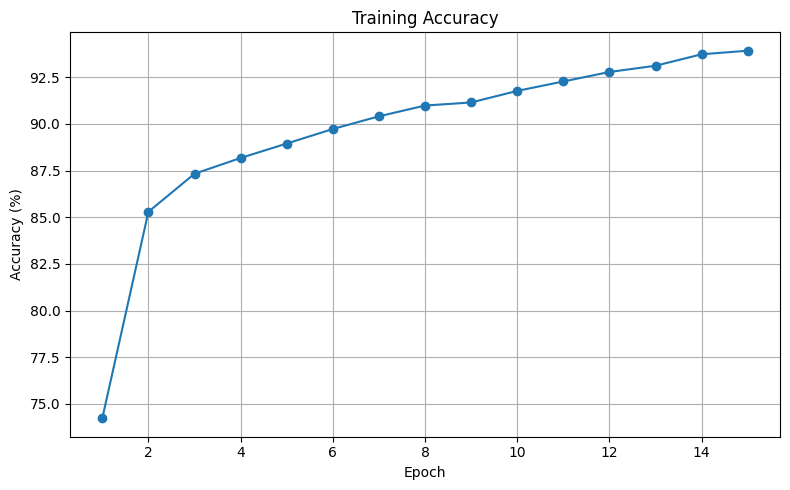

In [23]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)



plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    [acc * 100 for acc in history["train_acc"]],
    marker="o"
)

plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.grid(True)
plt.tight_layout()
plt.show()








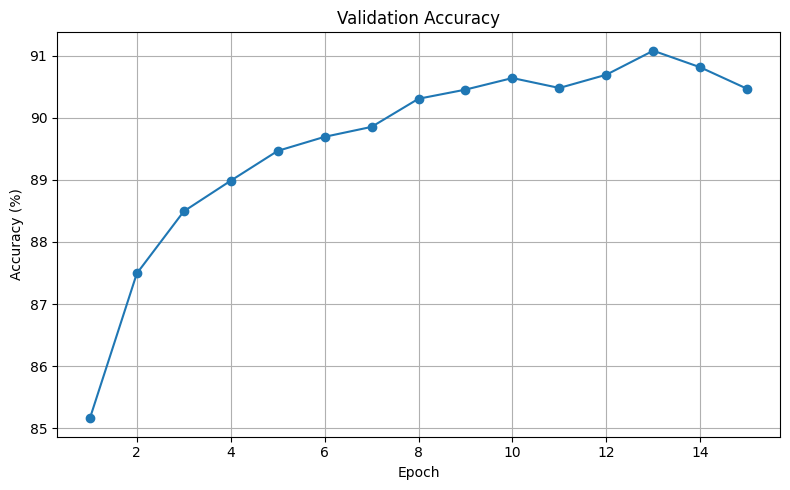

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    [acc * 100 for acc in history["val_acc"]],
    marker="o"
)

plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.grid(True)
plt.tight_layout()
plt.show()


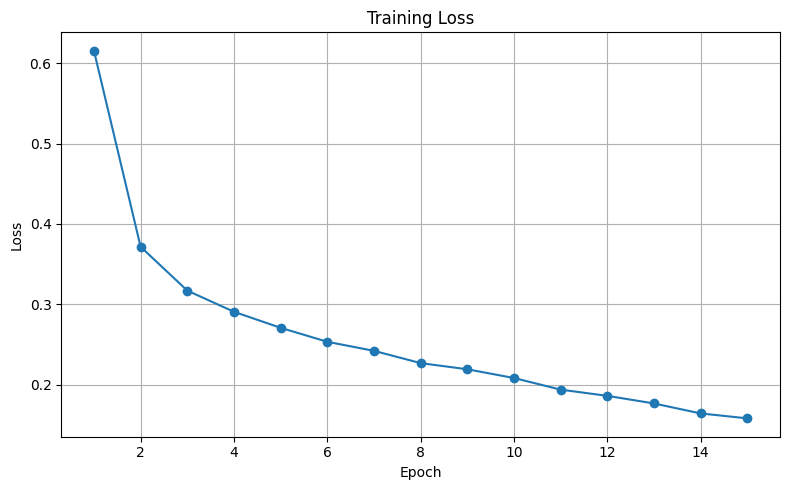

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o"
)

plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.tight_layout()
plt.show()

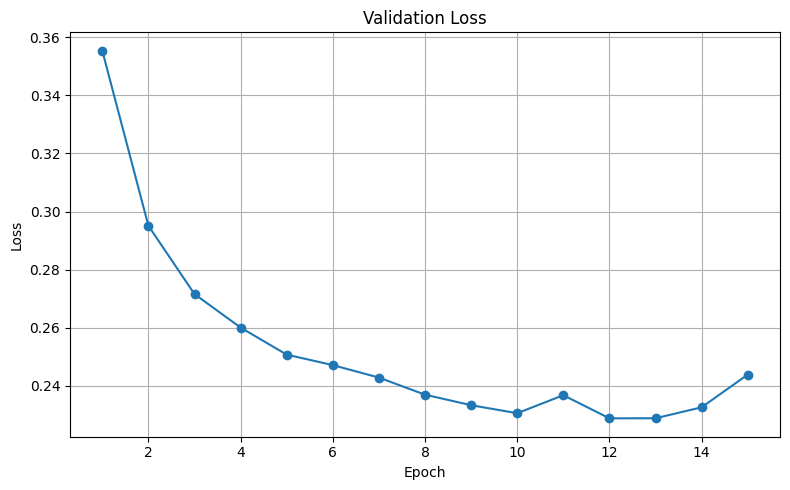

In [26]:
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["val_loss"],
    marker="o"
)

plt.title("Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.tight_layout()
plt.show()